# TD Colzette : template pour interface paramètres

Dans ce TP, nous explorons l'interception lumineuse dans un couvert végétal... blablabla

In [1]:
from openalea.plantgl.all import *
from openalea.colzette import Colzette, scenario_monocrop_brassica, scenario_intercrop_brassica_faba
import pandas as pd
import matplotlib.pyplot as plt
from openalea.widgets.plantgl import PlantGL


import os, sys
os.environ["PATH"] = os.pathsep.join(
    [os.path.join(sys.prefix, "Scripts"), os.path.join(sys.prefix, "Library", "bin"), os.environ["PATH"]])


In [2]:
rows = []
for p in Colzette.parameters():
    rows.append({
        "Nom": p.name,
        "Description": p.metadata["description"],
        "Défaut": p.default,
        "Min": p.metadata["min_value"],
        "Max": p.metadata["max_value"],
    })

df = pd.DataFrame(rows)
df

,Nom,Description,Défaut,Min,Max
0,coeff_width_leaf_brassica,coefficient for leaf width,0.415593,0.372964,0.464210
1,coeff_petiole_leaf_brassica,coefficient for petiole to leaf ratio,0.351519,0.278166,0.435531
2,ins_angle_brassica,insertion angle (degrees),38.082375,20.000000,50.000000
3,rmax_brassica,maximum relative growth rate,0.619420,0.559366,0.661634
4,k_brassica,curvature parameter,7.427711,3.277700,10.347996
5,growth_node_brassica,internode growth coefficient,0.000343,0.000198,0.000444
6,phyllot_brassica,phyllotaxis angle (degrees),137.500000,123.750000,151.250000
7,phylloc_brassica,phyllochron,0.012271,0.011102,0.013448
8,coeff_width_leaflet1_legume,coefficient for leaflet 1 width,0.690537,0.642424,0.744056
9,coeff_width_leaflet2_legume,coefficient for leaflet 2 width,0.525762,0.500000,0.565217


 ## Simulation Monoculture colza classique avec paramètres par défaut

In [3]:
rapeseed_monocrop = Colzette(**scenario_monocrop_brassica)
rapeseed_monocrop.run()

Running 99%

L'absorption cumulée par plant de colza au cours du temps

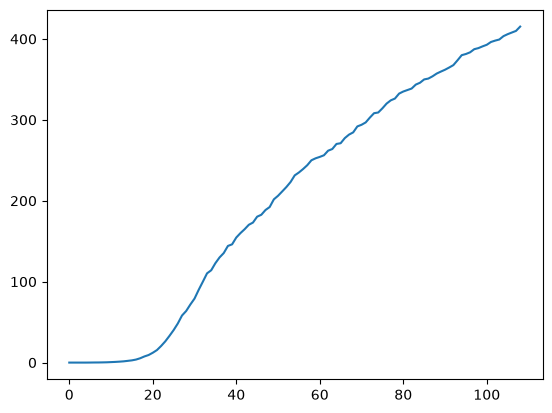

In [4]:
monocrop_outputs = rapeseed_monocrop.rapeseed_outputs
plt.plot(monocrop_outputs["DAS"], monocrop_outputs["absolute_energy_cum_plant"])

Absorption finale du colza

In [6]:
rapeseed_monocrop.last_day_rapeseed["absolute_energy_cum_plant"]

0    415.247395
Name: absolute_energy_cum_plant, dtype: float64

In [7]:
rapeseed_monocrop.plot_scene(day=108, variable="Ei", as_html=True) # last day absorption (J/m2) per organ

In [ ]:
rapeseed_faba_intercrop = Colzette(**scenario_intercrop_brassica_faba)
rapeseed_faba_intercrop.run()

## Simulation pour changer un paramètre

In [ ]:
c1_param = Colzette(coeff_petiole_leaf_brassica=0.43,ins_angle_brassica=39)
c1_param.run()
c1_param.agg["Eabs"]